# Queuing Models for Healthcare Services
### M/M/1, M/G/1 and M/M/s models applied to emergency, outpatient, surgical and laboratory scenarios

**Author:** Hataipon Pengkumma · MSc Health Data Science, University of Exeter (HPDM139)

**Contents:** [Summary](#summary) · [How to use](#howto) · [Introduction and aims](#intro) · [The models](#models) · [Python tools](#tools) · [Testing](#testing) · [Results](#results) · [Discussion](#discussion) · [References](#references)

<a id="summary"></a>
# Summary

Hospitals constantly balance how many staff and resources to provide against how long patients wait. This project uses simple mathematical "queuing" models to answer that kind of question quickly, using six realistic hospital examples.

The examples show three things. First, waiting does not rise evenly as a service gets busier. When an emergency department or clinic is close to full, a small rise in patient numbers causes a large jump in waiting: in one clinic, 29% more patients meant about five times as many people waiting. Second, unpredictable treatment times make queues much longer, even when the average treatment time stays the same. This is why a surgical department could only safely take slightly fewer patients than its full capacity. Third, the number of staff needed depends on the goal. Keeping the average wait in a blood-test department under one minute needed 38 staff, while keeping the department below 40 patients nine times out of ten needed 37.

The models assume patients arrive at random, are seen in order of arrival, and that conditions stay stable over time. Real hospitals have busy periods, urgent cases and limited space, so the results are best used as quick first estimates to guide planning rather than exact predictions.

<a id="howto"></a>
# How to use this notebook

Install the dependencies (`pip install -r requirements.txt`), open this notebook from the repository root, and run *Kernel → Restart & Run All*. No data files are needed.

| Package | Version tested | Purpose |
|---|---|---|
| Python | 3.10+ | |
| numpy, pandas, matplotlib | 1.24+ / 2.0+ / 3.7+ | Calculation, tables, figures |
| `queuing_models` | 1.0.0 (this repository) | The models, `Queue` class and validation |

To run a new scenario, create a `Queue`, then call `experiment()` for one parameter set or `experiment_df()` with a DataFrame of parameter sets (see [Python tools](#tools)). The units of the results follow the units of the rates: rates per hour give times in hours.

<a id="intro"></a>
# Introduction

Queuing theory, the mathematical study of waiting lines, has many applications in healthcare, from emergency departments to surgical waiting lists (Gupta, 2013). Its steady-state equations give exact answers instantly, which makes them useful for early capacity planning before investing in detailed simulation.

### Study aims

1. Implement the M/M/1, M/G/1 and M/M/s queuing models as a reusable, tested Python toolkit.
2. Apply the toolkit to six healthcare scenarios, each asking a concrete capacity question: what service rate, demand level or number of staff meets a target?
3. Draw out general lessons about utilisation, variability and staffing targets for service planning.

| # | Model | Setting | Question |
|---|---|---|---|
| 1 | M/M/1 | Emergency department | What service rate brings the mean wait below 30 minutes? |
| 2 | M/M/1 | Allergy clinic | How long is the queue if demand rises from 7 to 9 patients/day? |
| 3 | M/G/1 | Surgical department | What is the highest demand that keeps the mean wait below 4 weeks? |
| 4 | M/G/1 | Surgical department | Which of six operation types miss their waiting-time targets? |
| 5 | M/M/s | Phlebotomy department | How many phlebotomists keep the mean wait below 1 minute? |
| 6 | M/M/s | Phlebotomy department | How many keep the department below 40 patients 90% of the time? |

<a id="models"></a>
# The queuing models

In each model patients arrive at random, wait in a single first-come-first-served queue if every server is busy, are treated, and leave. Waiting space is unlimited.

- **M/M/1:** one server; times between arrivals and service times are exponentially distributed.
- **M/G/1:** one server; exponential times between arrivals, but service times follow a general distribution summarised by its coefficient of variation, $CV = \sigma / E(X)$.
- **M/M/s:** $s$ identical servers sharing one queue; exponential times between arrivals and service times.

| Symbol | Meaning |
|---|---|
| $\lambda$, $\mu$ | Mean arrival rate; mean service rate per server |
| $s$, $CV$ | Number of servers (M/M/s); coefficient of variation of service time (M/G/1) |
| $\rho$ | Traffic intensity (server utilisation) |
| $L_q$, $L_s$ | Expected number of patients in the queue / in the system |
| $W_q$, $W_s$ | Expected waiting time in the queue / time in the system |
| $p_n$ | Probability of exactly $n$ patients in the system |

The equations describe long-run averages and hold only in steady state, when $\rho = \lambda/(s\mu) < 1$. The queue length is model specific:

$$\begin{align}
\rho\ =&\ \frac{\lambda}{\mu}\ \text{(M/M/1, M/G/1)}, \qquad \frac{\lambda}{s\mu}\ \text{(M/M/s)}\\[1ex]
L_q\ =&\ \frac{\rho^2}{1-\rho}\ \text{(M/M/1)}, \qquad \frac{\rho^2}{1-\rho}\left(\frac{1 + CV^2}{2}\right)\ \text{(M/G/1)}, \qquad \frac{p_0\,(\lambda/\mu)^s\,\rho}{s!\,(1-\rho)^2}\ \text{(M/M/s)}\\[1ex]
p_0\ =&\ 1-\rho\ \text{(M/M/1, M/G/1)}, \qquad \Biggl[\sum_{n=0}^{s-1} \frac{(\lambda/\mu)^n}{n!}+ \frac{(\lambda/\mu)^s}{s!(1-\rho)}\Biggr]^{-1}\ \text{(M/M/s)}\\[1ex]
p_n\ =&\ (1-\rho)\rho^n\ \text{(M/M/1)}, \qquad \Biggl\{\begin{array}{cl}\dfrac{(\lambda/\mu)^n}{n!}p_0, & n \le s \\[1ex]
\dfrac{(\lambda/\mu)^n}{s!\,s^{n-s}}p_0, & n > s \end{array}\ \text{(M/M/s)}
\end{align}$$

The other measures follow for every model from Little's formula (Little, 1961):

$$W_q = \frac{L_q}{\lambda}, \qquad W_s = W_q + \frac{1}{\mu}, \qquad L_s = L_q + \frac{\lambda}{\mu}.$$

For M/G/1, the factor $(1+CV^2)/2$ (the Pollaczek–Khinchine correction) equals 1 for exponential service ($CV = 1$), recovering M/M/1.

<a id="tools"></a>
# Python tools for queuing experiments

The toolkit lives in the `queuing_models` package beside this notebook so that it can be imported and unit-tested. Its source is displayed below.

| Module | Contents |
|---|---|
| `exceptions.py` | `InvalidModelError`, `MissingColumnsError`, `InvalidParameterError` (all subclass `ValueError`) |
| `validation.py` | `validate_params()`: checks values and the steady-state condition |
| `formulas.py` | `compute_rho`, `compute_p0`, `compute_Lq`, `compute_Ls`, `compute_Wq`, `compute_Ws`, `compute_p`, `compute_metrics` |
| `queue.py` | The `Queue` class and `find_parameter()` for solving for a target |

In [1]:
import inspect

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Code, display

import queuing_models
from queuing_models import (
    InvalidModelError, InvalidParameterError, MissingColumnsError, Queue,
    compute_metrics, find_parameter, validate_params,
)
from queuing_models import formulas


def show_source(*objects) -> None:
    """Display the source code of package objects in the notebook."""
    for obj in objects:
        display(Code(inspect.getsource(obj), language="python"))


plt.rcParams.update({"figure.figsize": (7.5, 4.2), "figure.dpi": 110,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)
print(f"queuing_models {queuing_models.__version__}")

queuing_models 1.0.0


**Validation and exceptions.** Every calculation first calls `validate_params()`. Invalid values (non-positive rates, a non-integer number of servers, negative CV) or an unstable queue ($\rho \ge 1$) raise an `InvalidParameterError` with an explanation, instead of silently returning infinite or negative waiting times.

In [2]:
show_source(queuing_models.exceptions, validate_params)

"""Custom exceptions for the queuing models.

All exceptions subclass ``ValueError`` so callers can catch them either
specifically or as ordinary value errors.
"""


class InvalidModelError(ValueError):
    """Raised when an unknown model name is given."""


class MissingColumnsError(ValueError):
    """Raised when an experiment DataFrame lacks required columns."""


class InvalidParameterError(ValueError):
    """Raised when parameters are invalid or give no steady state."""

def validate_params(lambd: float, mu: float, s: int = 1, cv: float = 1.0) -> None:
    """Check queue parameters and raise if they are invalid or unstable.

    Parameters
    ----------
    lambd : float
        Mean arrival rate (> 0).
    mu : float
        Mean service rate per server (> 0).
    s : int, default 1
        Number of servers (integer >= 1).
    cv : float, default 1.0
        Coefficient of variation of service time (>= 0, M/G/1 only).

    Raises
    ------
    InvalidParameterError
        If any value is out of range or lambd / (s * mu) >= 1.
    """
    if not (_is_real_number(lambd) and _is_real_number(mu)):
        raise InvalidParameterError(
            f"lambd and mu must be finite numbers (got {lambd!r}, {mu!r})."
        )
    if not (lambd > 0 and mu > 0):
        raise InvalidParameterError(f"lambd and mu must be > 0 (got {lambd}, {mu}).")
    if isinstance(s, bool) or not isinstance(s, (int, np.integer)) or s < 1:
        raise InvalidParameterError(f"s must be an integer >= 1 (got {s!r}).")
    if not _is_real_number(cv) or cv < 0:
        raise InvalidParameterError(f"cv must be a finite number >= 0 (got {cv!r}).")
    rho = lambd / (s * mu)
    if rho >= 1:
        raise InvalidParameterError(
            f"rho = {rho:.3f} >= 1: no steady state. Lower lambd or add capacity."
        )

**Formulas.** One function per performance measure. $L_q$ is model specific; the remaining measures use Little's formula. The terms $(\lambda/\mu)^n/n!$ are built recursively rather than with `math.factorial`, which avoids overflow for large numbers of servers.

In [3]:
show_source(formulas.compute_rho, formulas.compute_p0, formulas.compute_Lq,
            formulas.compute_p, compute_metrics)

def compute_rho(model: str, lambd: float, mu: float, s: int = 1) -> float:
    """Return the traffic intensity: lambd / mu, or lambd / (s * mu) for M/M/s."""
    return lambd / mu if _check_model(model) in ("mm1", "mg1") else lambd / (s * mu)

def compute_p0(model: str, lambd: float, mu: float, s: int = 1) -> float:
    """Return the probability that the system is empty."""
    rho = compute_rho(model, lambd, mu, s)
    if _check_model(model) in ("mm1", "mg1"):
        return 1 - rho
    terms = _poisson_terms(lambd / mu, s)
    return 1 / (sum(terms[:s]) + terms[s] / (1 - rho))

def compute_Lq(model: str, lambd: float, mu: float, s: int = 1, cv: float = 1.0) -> float:
    """Return the expected number of patients waiting in the queue.

    Parameters
    ----------
    model : str
        ``"mm1"``, ``"mg1"`` or ``"mms"``.
    lambd, mu : float
        Mean arrival rate and mean service rate per server.
    s : int, default 1
        Number of servers (M/M/s only).
    cv : float, default 1.0
        Coefficient of variation of service time (M/G/1 only).

    Returns
    -------
    float
        Lq from the model's steady-state equation.
    """
    model = _check_model(model)
    rho = compute_rho(model, lambd, mu, s)
    if model == "mm1":
        return rho ** 2 / (1 - rho)
    if model == "mg1":
        return (rho ** 2 / (1 - rho)) * ((1 + cv ** 2) / 2)
    p0 = compute_p0(model, lambd, mu, s)
    a_s_over_s_fact = _poisson_terms(lambd / mu, s)[s]          # (lambd/mu)^s / s!
    return p0 * a_s_over_s_fact * rho / (1 - rho) ** 2

def compute_p(lambd: float, mu: float, s: int, n_max: int) -> list[float]:
    """Return [p0, p1, ..., p_{n_max - 1}] for an M/M/1 or M/M/s system.

    Parameters
    ----------
    lambd, mu : float
        Mean arrival rate and mean service rate per server.
    s : int
        Number of servers (1 for M/M/1).
    n_max : int
        Number of probabilities to return.

    Returns
    -------
    list of float
        p_n for n = 0..n_max - 1.
    """
    tau = lambd / mu
    p0 = compute_p0("mms", lambd, mu, s)
    terms = _poisson_terms(tau, min(n_max, s + 1))
    probs = []
    for n in range(n_max):
        if n <= s:
            probs.append(terms[n] * p0)
        else:
            probs.append(probs[-1] * tau / s)     # p_n = p_{n-1} * tau / s for n > s
    return probs

def compute_metrics(model: str, lambd: float, mu: float, s: int = 1,
                    cv: float = 1.0, n: int = 10) -> dict:
    """Validate the inputs and return every performance measure for one model run.

    Parameters
    ----------
    model : str
        ``"mm1"``, ``"mg1"`` or ``"mms"``.
    lambd, mu : float
        Mean arrival rate and mean service rate per server.
    s : int, default 1
        Number of servers. Must be 1 for M/M/1 and M/G/1.
    cv : float, default 1.0
        Coefficient of variation of service time. Must be 1 (exponential
        service) for M/M/1 and M/M/s.
    n : int, default 10
        Number of state probabilities p0..p_{n-1} to return (M/M/1, M/M/s).
        M/G/1 returns p0 only.

    Returns
    -------
    dict
        rho, Lq, Ls, Wq, Ws and p0 (plus p1.. for M/M/1 and M/M/s).

    Raises
    ------
    InvalidModelError
        If the model name is unknown.
    InvalidParameterError
        If the parameters are invalid, inconsistent with the model, or unstable.
    """
    model = _check_model(model)
    validate_params(lambd, mu, s, cv)
    if model in ("mm1", "mg1") and s != 1:
        raise InvalidParameterError(f"{model} has a single server; s must be 1 (got {s}).")
    if model in ("mm1", "mms") and cv != 1:
        raise InvalidParameterError(
            f"{model} assumes exponential service (cv = 1); use 'mg1' for cv = {cv}."
        )

    Lq = compute_Lq(model, lambd, mu, s, cv)
    Wq = compute_Wq(lambd, Lq)
    result = {
        "rho": compute_rho(model, lambd, mu, s),
        "Lq": Lq,
        "Ls": compute_Ls(lambd, mu, Lq),
        "Wq": Wq,
        "Ws": compute_Ws(mu, Wq),
    }
    if model == "mg1":
        result["p0"] = compute_p0(model, lambd, mu)
    else:
        result.update({f"p{i}": p for i, p in enumerate(compute_p(lambd, mu, s, max(n, 1)))})
    return result

**The `Queue` class.** All experiments use this class. `experiment()` runs one parameter set and `report()` prints it. `experiment_df()` runs a DataFrame of parameter sets and returns the results as a DataFrame; extra columns such as labels are kept. `find_parameter()` solves for the exact parameter value that meets a target, rather than reading the nearest value off a grid.

In [4]:
show_source(Queue, find_parameter)

class Queue:
    """A queuing experiment for one model.

    Parameters
    ----------
    model : str
        ``"mm1"``, ``"mg1"`` or ``"mms"`` (case-insensitive).

    Raises
    ------
    InvalidModelError
        If the model name is unknown.

    Examples
    --------
    >>> round(Queue("mm1").experiment(lambd=2, mu=3).results["Ls"], 6)
    2.0
    """

    def __init__(self, model: str):
        self._model = _check_model(model)
        self._params: dict = {}
        self._results: dict = {}
        self._result_df: pd.DataFrame | None = None

    @property
    def model(self) -> str:
        """The model name."""
        return self._model

    def experiment(self, lambd: float, mu: float, s: int = 1, cv: float = 1.0,
                   n: int = 10) -> "Queue":
        """Run the model for one set of parameters.

        Parameters
        ----------
        lambd : float
            Mean arrival rate.
        mu : float
            Mean service rate per server.
        s : int, default 1
            Number of servers (M/M/s only).
        cv : float, default 1.0
            Coefficient of variation of service time (M/G/1 only).
        n : int, default 10
            Number of state probabilities p0..p_{n-1} to compute.

        Returns
        -------
        Queue
            This instance, so calls can be chained, e.g.
            ``Queue("mm1").experiment(2, 3).report()``.

        Raises
        ------
        InvalidParameterError
            If the parameters are invalid or give no steady state.
        """
        self._results = compute_metrics(self._model, lambd, mu, s, cv, n)
        self._params = {"lambd": lambd, "mu": mu, "s": s, "cv": cv}
        return self

    @property
    def results(self) -> dict:
        """Performance measures from the last call to ``experiment``."""
        return dict(self._results)

    def report(self, n: int = 10, digits: int = 5) -> None:
        """Print the results of the last call to ``experiment``.

        Parameters
        ----------
        n : int, default 10
            Maximum number of state probabilities to show.
        digits : int, default 5
            Number of decimal places.
        """
        if not self._results:
            raise RuntimeError("Run experiment() before report().")
        lines = [f"The result of the experiment ({MODEL_LABELS[self._model]}):", ""]
        params = {"lambda": self._params["lambd"], "mu": self._params["mu"]}
        if self._model == "mms":
            params["s"] = self._params["s"]
        if self._model == "mg1":
            params["CV"] = self._params["cv"]
        lines += [f"{k} = {v:.{digits}f}" if isinstance(v, float) else f"{k} = {v}"
                  for k, v in params.items()]
        lines += [f"{k} = {self._results[k]:.{digits}f}"
                  for k in ["rho", "Lq", "Ls", "Wq", "Ws"]]
        probs = [round(v, digits) for k, v in self._results.items() if k.startswith("p")]
        lines.append(f"p0, p1, ..., pn = {probs[:n]}" if len(probs) > 1 else
                     f"p0 = {probs[0]:.{digits}f}")
        print("\n".join(lines))

    def experiment_df(self, df: pd.DataFrame, n: int = 10,
                      on_unstable: str = "raise") -> pd.DataFrame:
        """Run the model for every row of a DataFrame of parameters.

        Parameters
        ----------
        df : pandas.DataFrame
            One row per scenario, with columns ``lambd`` and ``mu`` (all models),
            ``cv`` (M/G/1) and ``s`` (M/M/s). Other columns are kept as labels.
        n : int, default 10
            Number of state probabilities p0..p_{n-1} to compute.
        on_unstable : {"raise", "flag"}, default "raise"
            ``"raise"`` stops at the first invalid or unstable row.
            ``"flag"`` records it with ``stable = False`` and missing results,
            so a sweep can safely cross the stability boundary.

        Returns
        -------
        pandas.DataFrame
            The input columns followed

def find_parameter(model: str, vary: str, metric: str, target: float,
                   lower: float, upper: float, tol: float = 1e-10,
                   **fixed) -> float:
    """Find the parameter value at which a performance measure reaches a target.

    Uses bisection, so ``metric`` must cross ``target`` exactly once between
    ``lower`` and ``upper``. This gives an exact answer rather than reading
    the nearest value off a grid.

    Parameters
    ----------
    model : str
        ``"mm1"``, ``"mg1"`` or ``"mms"``.
    vary : str
        Name of the parameter to solve for, e.g. ``"mu"`` or ``"lambd"``.
    metric : str
        Performance measure to match, e.g. ``"Wq"``.
    target : float
        Required value of ``metric``.
    lower, upper : float
        Search interval for ``vary``; both ends must give a stable queue.
    tol : float, default 1e-10
        Width of the final interval.
    **fixed
        Other parameters of ``compute_metrics``, held constant.

    Returns
    -------
    float
        The value of ``vary`` at which ``metric == target``.

    Examples
    --------
    >>> round(find_parameter("mm1", "mu", "Wq", 0.5, 4.01, 10, lambd=4), 3)
    5.464
    """
    f: Callable[[float], float] = (
        lambda x: compute_metrics(model, **{**fixed, vary: x})[metric] - target
    )
    f_lo, f_hi = f(lower), f(upper)
    if np.sign(f_lo) == np.sign(f_hi):
        raise ValueError(f"{metric} does not cross {target} between {lower} and {upper}.")
    while upper - lower > tol:
        mid = (lower + upper) / 2
        if np.sign(f(mid)) == np.sign(f_lo):
            lower = mid
        else:
            upper = mid
    return (lower + upper) / 2

### Example usage

Each experiment begins by creating a `Queue` with a model name. A single experiment can be run and printed in one line:

In [5]:
Queue("mm1").experiment(lambd=3, mu=4).report(n=12)

The result of the experiment (M/M/1):

lambda = 3
mu = 4
rho = 0.75000
Lq = 2.25000
Ls = 3.00000
Wq = 0.75000
Ws = 1.00000
p0, p1, ..., pn = [0.25, 0.1875, 0.14062, 0.10547, 0.0791, 0.05933, 0.04449, 0.03337, 0.02503, 0.01877]


In [6]:
Queue("mms").experiment(lambd=2, mu=7, s=2).report(digits=3)

The result of the experiment (M/M/s):

lambda = 2
mu = 7
s = 2
rho = 0.143
Lq = 0.006
Ls = 0.292
Wq = 0.003
Ws = 0.146
p0, p1, ..., pn = [0.75, 0.214, 0.031, 0.004, 0.001, 0.0, 0.0, 0.0, 0.0, 0.0]


Full-scale experiments use `experiment_df()` with a DataFrame of input parameters:

In [7]:
mg1_demo = Queue("mg1")
mg1_demo.experiment_df(pd.DataFrame({"lambd": [2, 3, 4], "mu": [3, 4, 5], "cv": [2, 3, 2]}))

,lambd,mu,cv,stable,rho,Lq,Ls,Wq,Ws,p0
0,2,3,2,True,0.667,3.333,4.0,1.667,2.0,0.333
1,3,4,3,True,0.750,11.250,12.0,3.750,4.0,0.250
2,4,5,2,True,0.800,8.000,8.8,2.000,2.2,0.200


Invalid or unstable inputs raise an informative error by default. With `on_unstable="flag"` they are recorded instead, so a sweep can cross the stability boundary:

In [8]:
try:
    Queue("mm1").experiment(lambd=3, mu=3)
except InvalidParameterError as err:
    print(f"InvalidParameterError: {err}")

Queue("mm1").experiment_df(pd.DataFrame({"lambd": [2, 3, 4], "mu": [3, 3, 3]}),
                           on_unstable="flag")[["lambd", "mu", "stable", "Wq"]]

InvalidParameterError: rho = 1.000 >= 1: no steady state. Lower lambd or add capacity.


,lambd,mu,stable,Wq
0,2,3,True,0.667
1,3,3,False,NaN
2,4,3,False,NaN


<a id="testing"></a>
# Testing

The cell below checks that the toolkit reproduces the worked examples in the technical appendix (Monks, 2024), satisfies Little's formula, agrees across models where theory says it must, and rejects bad input. The same checks run automatically with `pytest` (`tests/test_queuing_models.py`) on every push to GitHub.

In [9]:
def check(condition: bool, description: str) -> None:
    """Print PASS/FAIL for a test and stop the notebook if it fails."""
    print(f"{'PASS' if condition else 'FAIL'}  {description}")
    assert condition, description


def raises(exc: type, func, *args, **kwargs) -> bool:
    """Return True if calling func(*args, **kwargs) raises exc."""
    try:
        func(*args, **kwargs)
    except exc:
        return True
    return False


close = lambda a, b: np.isclose(a, b, rtol=1e-9)

r = Queue("mm1").experiment(2, 3).results
check(close(r["Ls"], 2) and close(r["Ws"], 1) and close(r["Wq"], 2 / 3),
      "Appendix M/M/1 example: Ls = 2, Ws = 1, Wq = 2/3")
r = Queue("mg1").experiment(1.5, 2, cv=(20 / 60) / 0.5).results
check(close(r["Lq"], 1.625) and close(r["Ls"], 2.375) and close(r["Wq"], 1.625 / 1.5),
      "Appendix M/G/1 example: Lq = 1.625, Ls = 2.375, Wq = 1.08")
r = Queue("mms").experiment(2, 3, s=2).results
check(close(r["p0"], 0.5) and close(r["Lq"], 1 / 12) and close(r["Wq"], 1 / 24),
      "Appendix M/M/2 example: p0 = 1/2, Lq = 1/12, Wq = 1/24")

for lam, mu, s in [(2, 3, 2), (9.5, 2, 5), (30, 1, 33)]:
    r = Queue("mms").experiment(lam, mu, s=s).results
    check(close(r["Ls"], lam * r["Ws"]), f"Little's formula Ls = lambda * Ws (s = {s})")

a, b = Queue("mm1").experiment(2, 3).results, Queue("mg1").experiment(2, 3, cv=1).results
c = Queue("mms").experiment(2, 3, s=1).results
check(all(close(a[k], b[k]) and close(a[k], c[k]) for k in ["Lq", "Ls", "Wq", "Ws", "p0"]),
      "M/M/1 = M/G/1 (CV = 1) = M/M/s (s = 1)")
check(close(sum(compute_metrics("mms", 9, 2, s=5, n=2000)[f"p{i}"] for i in range(2000)), 1),
      "M/M/s probabilities p_n sum to 1")
check(np.isfinite(Queue("mms").experiment(190, 1, s=200).results["Lq"]),
      "No overflow with 200 servers")

check(raises(InvalidParameterError, Queue("mm1").experiment, 3, 3), "rho = 1 rejected")
check(raises(InvalidParameterError, Queue("mm1").experiment, 4, 0), "mu = 0 rejected")
check(raises(InvalidParameterError, Queue("mg1").experiment, 1, 2, cv=-3), "Negative CV rejected")
check(raises(InvalidParameterError, Queue("mms").experiment, 2, 3, s=2.5), "Non-integer s rejected")
check(raises(InvalidModelError, Queue, "mm2"), "Unknown model name rejected")
check(raises(MissingColumnsError, Queue("mg1").experiment_df, pd.DataFrame({"lambd": [1], "mu": [2]})),
      "Missing DataFrame column rejected")

PASS  Appendix M/M/1 example: Ls = 2, Ws = 1, Wq = 2/3
PASS  Appendix M/G/1 example: Lq = 1.625, Ls = 2.375, Wq = 1.08
PASS  Appendix M/M/2 example: p0 = 1/2, Lq = 1/12, Wq = 1/24
PASS  Little's formula Ls = lambda * Ws (s = 2)
PASS  Little's formula Ls = lambda * Ws (s = 5)
PASS  Little's formula Ls = lambda * Ws (s = 33)
PASS  M/M/1 = M/G/1 (CV = 1) = M/M/s (s = 1)


PASS  M/M/s probabilities p_n sum to 1
PASS  No overflow with 200 servers
PASS  rho = 1 rejected
PASS  mu = 0 rejected
PASS  Negative CV rejected
PASS  Non-integer s rejected
PASS  Unknown model name rejected
PASS  Missing DataFrame column rejected


<a id="results"></a>
# Results

The helper below draws each experiment's result with the current situation and the target marked, so every figure reads the same way.

In [10]:
def plot_with_target(df, x, y, current, target, answer, xlabel, ylabel, title,
                     answer_label, colour="tab:green", target_label="Target"):
    """Plot y against x with the current state and the target answer marked.

    Parameters
    ----------
    df : pandas.DataFrame
        Experiment results.
    x, y : str
        Columns to plot.
    current : tuple of float
        (x, y) for the current situation.
    target : float
        Target value of y.
    answer : float
        Value of x that meets the target.
    xlabel, ylabel, title, answer_label : str
        Axis labels, title and legend label for the answer.
    colour : str
        Colour for the target and answer lines.
    target_label : str
        Legend label for the horizontal line.
    """
    fig, ax = plt.subplots()
    ax.plot(df[x], df[y], lw=2, color="tab:blue")
    ax.plot(*current, "o", color="black", label=f"Current: {xlabel.split(' (')[0]} = {current[0]:g}")
    ax.axhline(target, color=colour, ls="--", label=f"{target_label}: {target:.2f}")
    ax.axvline(answer, color=colour, ls=":", label=f"{answer_label} = {answer:.2f}")
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.legend()
    plt.show()

## 1. M/M/1 model

The M/M/1 model is a reasonable choice for single-server services such as outpatient clinics, pharmacies and patient registration (Gupta, 2013).

### Experiment 1 — Emergency department service rate

**Scenario.** An emergency department sees a mean of $\lambda = 4$ patients/hour at a mean service rate of $\mu = 4.5$ patients/hour, giving a mean wait in the queue of $W_q = 1.78$ hours. Extra resources and better triage should raise the service rate. The head of department wants the mean wait below 0.5 hours (30 minutes).

**Question.** What service rate is needed to meet this target?

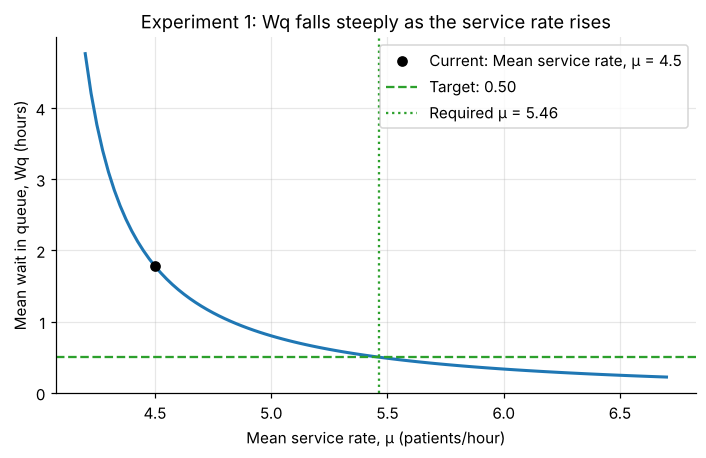

Current Wq = 1.78 h. Required mu = 5.46 patients/hour (+21%).


In [11]:
E1_LAMBDA, E1_MU_NOW, E1_TARGET_WQ = 4, 4.5, 0.5

mm1_exp1 = Queue("mm1")
mm1_df1 = pd.DataFrame({"lambd": E1_LAMBDA, "mu": np.linspace(4.2, 6.7, 101)})
mm1_exp1.experiment_df(mm1_df1, n=5)

e1_wq_now = Queue("mm1").experiment(E1_LAMBDA, E1_MU_NOW).results["Wq"]
e1_mu = find_parameter("mm1", "mu", "Wq", E1_TARGET_WQ, lower=E1_LAMBDA + 0.01, upper=10,
                       lambd=E1_LAMBDA)

plot_with_target(mm1_exp1.result_df, "mu", "Wq", (E1_MU_NOW, e1_wq_now), E1_TARGET_WQ, e1_mu,
                 "Mean service rate, μ (patients/hour)", "Mean wait in queue, Wq (hours)",
                 "Experiment 1: Wq falls steeply as the service rate rises", "Required μ")
print(f"Current Wq = {e1_wq_now:.2f} h. Required mu = {e1_mu:.2f} patients/hour "
      f"(+{100 * (e1_mu / E1_MU_NOW - 1):.0f}%).")

**Result.** The service rate must rise to at least **5.46 patients/hour**, a 21% increase on the current 4.5, to bring the mean wait below 30 minutes. This cuts the mean wait by 72%, from 1.78 hours. The curve flattens as the service rate rises, so further capacity gives smaller gains.

### Experiment 2 — Seasonal demand at an allergy clinic

**Scenario.** An outpatient allergy clinic sees about $\lambda = 7$ patients/day in summer and winter, with a service rate of $\mu = 10$ patients/day, giving $L_q = 1.63$ patients waiting. Demand rises in spring and autumn.

**Question.** How many patients will be waiting on average if demand rises to 9 patients/day?

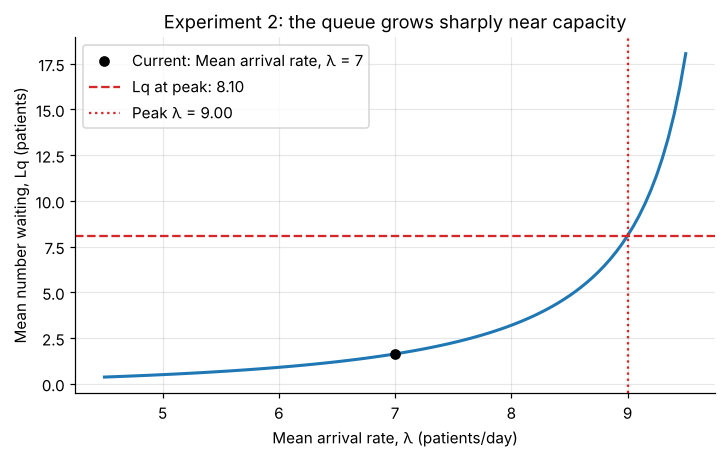

Lq at lambda = 7: 1.63; at lambda = 9: 8.10 (5.0 times larger).


In [12]:
E2_MU, E2_LAMBDA_NOW, E2_LAMBDA_PEAK = 10, 7, 9

mm1_exp2 = Queue("mm1")
mm1_df2 = pd.DataFrame({"lambd": np.linspace(4.5, 9.5, 101), "mu": E2_MU})
mm1_exp2.experiment_df(mm1_df2, n=5)

e2_now = Queue("mm1").experiment(E2_LAMBDA_NOW, E2_MU).results["Lq"]
e2_peak = Queue("mm1").experiment(E2_LAMBDA_PEAK, E2_MU).results["Lq"]

plot_with_target(mm1_exp2.result_df, "lambd", "Lq", (E2_LAMBDA_NOW, e2_now), e2_peak,
                 E2_LAMBDA_PEAK, "Mean arrival rate, λ (patients/day)",
                 "Mean number waiting, Lq (patients)",
                 "Experiment 2: the queue grows sharply near capacity", "Peak λ",
                 colour="tab:red", target_label="Lq at peak")
print(f"Lq at lambda = 7: {e2_now:.2f}; at lambda = 9: {e2_peak:.2f} "
      f"({e2_peak / e2_now:.1f} times larger).")

**Result.** A 29% rise in demand, from 7 to 9 patients/day, increases the mean number waiting from 1.63 to **8.10**, about five times as many. At 70% utilisation the clinic looks comfortable but is close to a steep rise in waiting, so seasonal peaks need planning explicitly.

## 2. M/G/1 model

In Markovian models the standard deviation of service time equals its mean. In many healthcare services it does not. Surgical procedure times, for example, are often right-skewed and highly variable (Gupta, 2013). The M/G/1 model captures this through the coefficient of variation (CV).

### Experiment 3 — Maximum surgical demand

**Scenario.** A surgical department completes on average $\mu = 22$ operations per week. Operation times are highly variable, with a standard deviation twice the mean ($CV = 2$). Demand is currently $\lambda = 20.8$ patients/week, giving a mean wait of about 2 weeks, and is gradually increasing.

**Question.** What is the highest demand the department can accept while keeping the mean wait below 4 weeks?

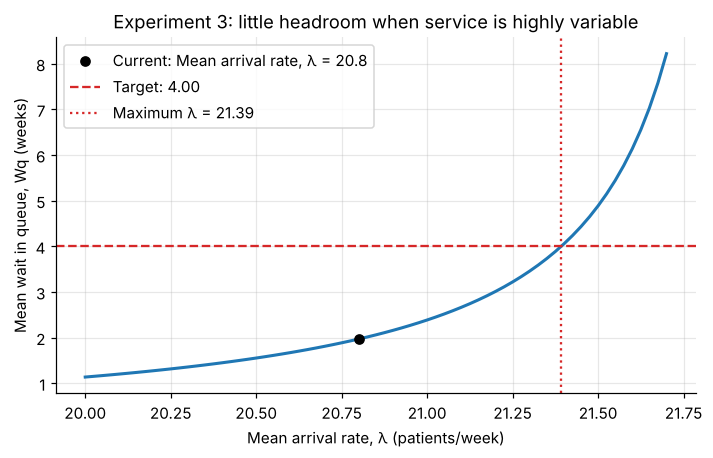

Current Wq = 1.97 weeks. Maximum lambda = 21.39 patients/week (utilisation 97.2%).


In [13]:
E3_MU, E3_CV, E3_LAMBDA_NOW, E3_TARGET_WQ = 22, 2.0, 20.8, 4

mg1_exp1 = Queue("mg1")
mg1_df1 = pd.DataFrame({"lambd": np.linspace(20, 21.7, 69), "mu": E3_MU, "cv": E3_CV})
mg1_exp1.experiment_df(mg1_df1)

e3_wq_now = Queue("mg1").experiment(E3_LAMBDA_NOW, E3_MU, cv=E3_CV).results["Wq"]
e3_lambda = find_parameter("mg1", "lambd", "Wq", E3_TARGET_WQ, lower=20, upper=21.99,
                           mu=E3_MU, cv=E3_CV)

plot_with_target(mg1_exp1.result_df, "lambd", "Wq", (E3_LAMBDA_NOW, e3_wq_now), E3_TARGET_WQ,
                 e3_lambda, "Mean arrival rate, λ (patients/week)",
                 "Mean wait in queue, Wq (weeks)",
                 "Experiment 3: little headroom when service is highly variable",
                 "Maximum λ", colour="tab:red")
print(f"Current Wq = {e3_wq_now:.2f} weeks. Maximum lambda = {e3_lambda:.2f} patients/week "
      f"(utilisation {e3_lambda / E3_MU:.1%}).")

**Result.** Demand can rise to at most **21.39 patients/week** before the mean wait exceeds 4 weeks, only 0.6 patients/week above current demand. With $CV = 2$, the correction factor $(1 + CV^2)/2 = 2.5$ makes waits 2.5 times longer than M/M/1 would predict, which leaves very little headroom even at 97% utilisation.

### Experiment 4 — Which operation types miss their targets?

**Scenario.** The surgical department performs six types of operation, with targets for the mean wait that depend on demand:

- $\lambda < 6$ patients/week: $W_q$ below 4 weeks
- $6 \le \lambda \le 12$ patients/week: $W_q$ below 3 weeks
- $\lambda > 12$ patients/week: $W_q$ below 2 weeks

**Question.** Which operation types miss their target and should be prioritised for more resources?

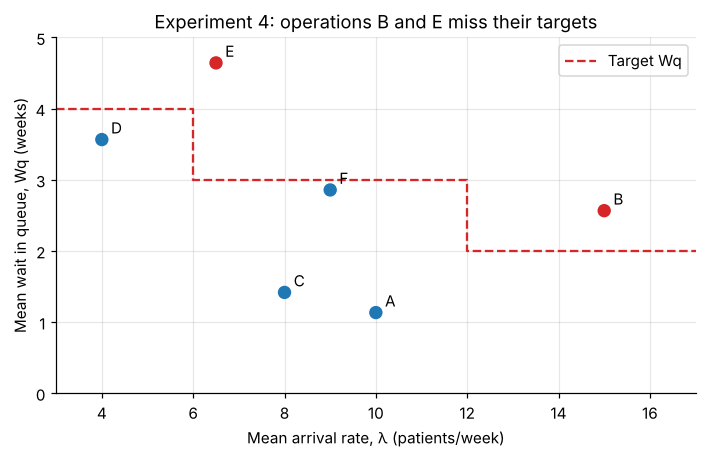

,operation,lambd,mu,cv,rho,Wq,target_Wq,meets_target
0,A,10.0,15.0,4,0.67,1.13,3,True
1,B,15.0,19.0,5,0.79,2.57,2,False
2,C,8.0,12.0,4,0.67,1.42,3,True
3,D,4.0,5.1,3,0.78,3.57,4,True
4,E,6.5,7.0,2,0.93,4.64,3,False
5,F,9.0,10.5,3,0.86,2.86,3,True


In [14]:
def target_wq(lambd: float) -> float:
    """Return the department's target mean wait (weeks) for a given demand."""
    return 4 if lambd < 6 else (3 if lambd <= 12 else 2)


mg1_exp2 = Queue("mg1")
mg1_df2 = pd.DataFrame({
    "operation": ["A", "B", "C", "D", "E", "F"],
    "lambd": [10, 15, 8, 4, 6.5, 9],
    "mu": [15, 19, 12, 5.1, 7, 10.5],
    "cv": [4, 5, 4, 3, 2, 3],
})
e4 = mg1_exp2.experiment_df(mg1_df2)
e4["target_Wq"] = e4["lambd"].apply(target_wq)
e4["meets_target"] = e4["Wq"] < e4["target_Wq"]

fig, ax = plt.subplots()
colours = np.where(e4["meets_target"], "tab:blue", "tab:red")
ax.scatter(e4["lambd"], e4["Wq"], c=colours, s=60, zorder=3)
for _, row in e4.iterrows():
    ax.annotate(row["operation"], (row["lambd"], row["Wq"]), xytext=(6, 4),
                textcoords="offset points")
ax.step([3, 6, 12, 17], [4, 3, 2, 2], where="post", color="tab:red", ls="--",
        label="Target Wq")
ax.set(xlim=(3, 17), ylim=(0, 5), xlabel="Mean arrival rate, λ (patients/week)",
       ylabel="Mean wait in queue, Wq (weeks)",
       title="Experiment 4: operations B and E miss their targets")
ax.legend()
plt.show()

e4[["operation", "lambd", "mu", "cv", "rho", "Wq", "target_Wq", "meets_target"]].round(2)

**Result.** Operations **B and E** miss their targets. E has the highest utilisation ($\rho = 0.93$, $W_q = 4.6$ weeks against a 3-week target). B has moderate utilisation ($\rho = 0.79$) but very variable operation times ($CV = 5$), giving $W_q = 2.6$ weeks against a 2-week target. Operations A and C have the same utilisation ($\rho = 0.67$) and CV but different waits, because A's higher service rate makes each operation shorter in absolute terms.

## 3. M/M/s model

The M/M/s model suits multi-server services such as walk-in clinics, pharmacy and laboratory services, and emergency departments (Gupta, 2013).

### Experiment 5 — Phlebotomists needed for a 1-minute mean wait

**Scenario.** A hospital phlebotomy department has 33 phlebotomists. Patients arrive at $\lambda = 30$ per hour and each phlebotomist completes on average $\mu = 1$ patient per hour, including registration, collection and sample handling. The mean wait in the queue is currently 9.8 minutes.

**Question.** What is the minimum number of phlebotomists that keeps the mean wait below 1 minute?

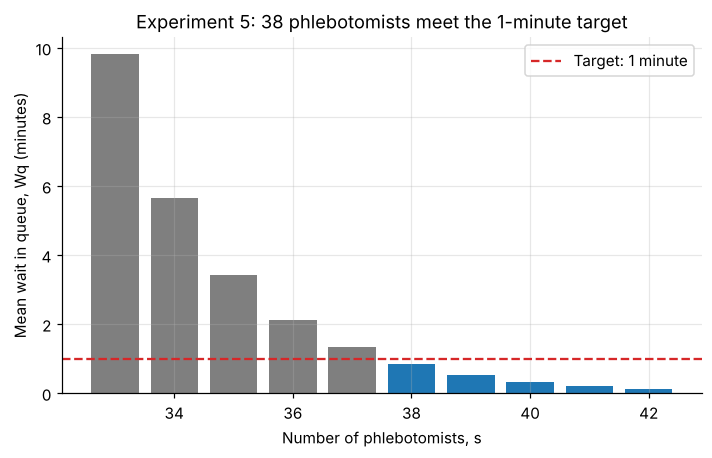

,s,rho,Lq,Wq_min
0,33,0.909,4.905,9.810
1,34,0.882,2.823,5.646
2,35,0.857,1.707,3.415
3,36,0.833,1.059,2.119
4,37,0.811,0.665,1.331
5,38,0.789,0.420,0.839
6,39,0.769,0.264,0.529
7,40,0.750,0.166,0.331
8,41,0.732,0.103,0.206
9,42,0.714,0.064,0.127


In [15]:
E5_LAMBDA, E5_MU, E5_TARGET_WQ_MIN = 30, 1, 1
E5_SERVERS = range(33, 43)

mms_exp1 = Queue("mms")
mms_df1 = pd.DataFrame({"lambd": E5_LAMBDA, "mu": E5_MU, "s": E5_SERVERS})
e5 = mms_exp1.experiment_df(mms_df1, n=2)
e5["Wq_min"] = e5["Wq"] * 60                     # rates are per hour, so Wq is in hours
e5_s = int(e5.loc[e5["Wq_min"] < E5_TARGET_WQ_MIN, "s"].min())

fig, ax = plt.subplots()
ax.bar(e5["s"], e5["Wq_min"], color=np.where(e5["s"] >= e5_s, "tab:blue", "tab:gray"))
ax.axhline(E5_TARGET_WQ_MIN, color="tab:red", ls="--", label="Target: 1 minute")
ax.set(xlabel="Number of phlebotomists, s", ylabel="Mean wait in queue, Wq (minutes)",
       title=f"Experiment 5: {e5_s} phlebotomists meet the 1-minute target")
ax.legend()
plt.show()
e5[["s", "rho", "Lq", "Wq_min"]].round(3)

**Result.** At least **38 phlebotomists** are needed, reducing the mean wait from 9.8 to 0.84 minutes. Each additional phlebotomist saves less time than the one before.

### Experiment 6 — Phlebotomists needed to limit crowding

**Scenario.** For the same department, the head of department sets a second goal: the department should hold fewer than 40 patients (waiting or being served) at least 90% of the time, i.e. $P(n \ge 40) = 1 - (p_0 + p_1 + \dots + p_{39}) < 0.1$.

**Question.** How many phlebotomists are needed to meet this goal?

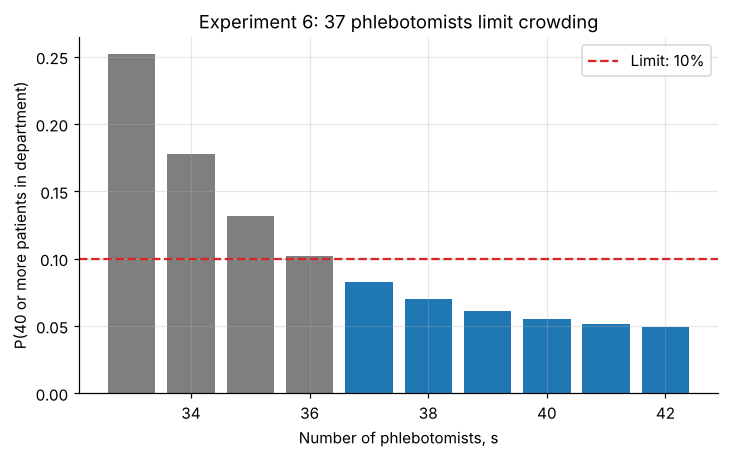

,s,rho,Ls,P_crowded
0,33,0.909,34.905,0.252
1,34,0.882,32.823,0.178
2,35,0.857,31.707,0.132
3,36,0.833,31.059,0.102
4,37,0.811,30.665,0.083
5,38,0.789,30.420,0.070
6,39,0.769,30.264,0.061
7,40,0.750,30.166,0.055
8,41,0.732,30.103,0.052
9,42,0.714,30.064,0.049


In [16]:
E6_MAX_PATIENTS, E6_MAX_PROB = 40, 0.1

mms_exp2 = Queue("mms")
mms_df2 = mms_df1.copy()
e6 = mms_exp2.experiment_df(mms_df2, n=E6_MAX_PATIENTS)
prob_cols = [f"p{i}" for i in range(E6_MAX_PATIENTS)]
e6["P_crowded"] = 1 - e6[prob_cols].sum(axis=1)  # P(n >= 40)
e6_s = int(e6.loc[e6["P_crowded"] < E6_MAX_PROB, "s"].min())

fig, ax = plt.subplots()
ax.bar(e6["s"], e6["P_crowded"], color=np.where(e6["s"] >= e6_s, "tab:blue", "tab:gray"))
ax.axhline(E6_MAX_PROB, color="tab:red", ls="--", label="Limit: 10%")
ax.set(xlabel="Number of phlebotomists, s", ylabel="P(40 or more patients in department)",
       title=f"Experiment 6: {e6_s} phlebotomists limit crowding")
ax.legend()
plt.show()
e6[["s", "rho", "Ls", "P_crowded"]].round(3)

**Result.** At least **37 phlebotomists** are needed: with 36, the department holds 40 or more patients 10.2% of the time, just above the limit. This goal needs one fewer phlebotomist than the mean-wait target in Experiment 5.

## Summary of results

In [17]:
pd.DataFrame([
    ("1", "M/M/1", "Service rate for Wq < 30 min", f"μ ≥ {e1_mu:.2f} patients/hour"),
    ("2", "M/M/1", "Lq when λ rises 7 → 9/day", f"{e2_now:.2f} → {e2_peak:.2f} patients"),
    ("3", "M/G/1", "Maximum λ for Wq < 4 weeks", f"λ ≤ {e3_lambda:.2f} patients/week"),
    ("4", "M/G/1", "Operations missing targets", ", ".join(e4.loc[~e4.meets_target, "operation"])),
    ("5", "M/M/s", "Staff for Wq < 1 min", f"{e5_s} phlebotomists"),
    ("6", "M/M/s", "Staff for P(n ≥ 40) < 10%", f"{e6_s} phlebotomists"),
], columns=["Experiment", "Model", "Question", "Answer"]).set_index("Experiment")

,Model,Question,Answer
Experiment,,,
1,M/M/1,Service rate for Wq < 30 min,μ ≥ 5.46 patients/hour
2,M/M/1,Lq when λ rises 7 → 9/day,1.63 → 8.10 patients
3,M/G/1,Maximum λ for Wq < 4 weeks,λ ≤ 21.39 patients/week
4,M/G/1,Operations missing targets,"B, E"
5,M/M/s,Staff for Wq < 1 min,38 phlebotomists
6,M/M/s,Staff for P(n ≥ 40) < 10%,37 phlebotomists


<a id="discussion"></a>
# Discussion

In this work I built a Python toolkit for the M/M/1, M/G/1 and M/M/s queuing models and used it to answer six capacity questions in emergency, outpatient, surgical and laboratory settings.

**Main findings**

- **Waiting grows non-linearly with utilisation (M/M/1).** In Experiment 1, a 21% increase in service rate cut the mean wait by 72%, and the gains shrank as the service rate rose further. In Experiment 2, a 29% rise in demand made the queue about five times longer. A service at 70% utilisation can look comfortable but be close to a steep rise in waiting, so peaks should be planned for explicitly.
- **Service-time variability matters as much as the average (M/G/1).** With $CV = 2$, waits were 2.5 times longer than M/M/1 would predict, so the surgical department could accept at most 21.39 patients/week against a capacity of 22. In Experiment 4, operation B missed its target mainly because of its high variability ($CV = 5$), not its utilisation. Standardising pathways or scheduling similar cases together could therefore be as effective as adding capacity.
- **The staffing answer depends on the target (M/M/s).** A 1-minute mean wait needed 38 phlebotomists, while limiting crowding needed 37. Means and tail probabilities answer different questions, so the target should match the risk the department cares about.

**Strengths**

The `Queue` class works with one parameter set or a whole DataFrame, so a new scenario needs only a new table of inputs. All inputs are validated, unstable queues raise clear errors, and the toolkit reproduces the appendix worked examples in an automated test suite. Targets are found exactly by bisection rather than read off a grid. The formulas give results instantly and are easy to explain to clinical managers.

**Limitations**

1. **Model assumptions.** All three models assume Poisson arrivals, unlimited waiting space, first-come-first-served service and steady state. Real demand has daily and seasonal patterns, no-shows, triage priorities and limited capacity, so steady-state results will understate peak-period delays.
2. **Illustrative parameters.** The scenario values are plausible but not estimated from data, so the results illustrate principles rather than describe real services.
3. **No uncertainty analysis.** In practice λ and μ are estimated from data, but results are shown as single numbers. Sensitivity analysis or confidence intervals would show how robust the conclusions are.
4. **Missing models.** There are no finite-capacity (M/M/s/K), priority or M/G/s models. M/M/s assumes exponential service times, which Experiment 4 suggests is unrealistic for highly variable services.

**Further work** could add simulation for time-varying demand, finite-capacity and priority models, and sensitivity analysis, so that the toolkit can support real operational decisions.

### AI use statement

Claude (Anthropic) was used to help refactor the code into a tested package, check calculations and edit the text. The author designed the study, scenarios and toolkit, reviewed all changes and takes responsibility for the final content.

<a id="references"></a>
# References

1. Gupta, D. (2013) 'Queueing models for healthcare operations', in Denton, B.T. (ed.) *Handbook of Healthcare Operations Management*. International Series in Operations Research & Management Science, vol. 184. New York: Springer, pp. 19–44.
2. Little, J.D.C. (1961) 'A proof for the queuing formula: L = λW', *Operations Research*, 9(3), pp. 383–387.
3. Monks, T. (2024) *HPDM139 Assignment 1: Technical Appendix*. University of Exeter, College of Medicine and Health.